# Speech command classification

This experiment uses local Speech Commands WAV files in `speech_commands/<class>/`. The dataset and pretrained model weights are not included. Training, validation and test partitions are disjoint at the file level. The local filenames do not preserve speaker identifiers, so the split cannot guarantee separation by speaker; scores can overestimate performance on new speakers. The saved results were generated on Kaggle with the corrected split and evaluated on the held-out test files.

**Data:** A local seven-class speech-command WAV collection under `speech_commands/<class>/`. The exact original public source is not confirmed. The exact files used in the saved experiments are not included; provide a compatible seven-class collection to run the notebook.

## Аудио → мел-спектрограмма → преобразование в изображение 224×224 → классифицировать её с помощью Vision Transforme (ViT) → классификатор

используется Vision Transformer Base / 16 обученная на ImageNet

In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchaudio.transforms as T
from torchvision import transforms as TV
from torchvision.models import vit_b_16, ViT_B_16_Weights
from pathlib import Path
from tqdm.auto import tqdm
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import soundfile as sf

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

DATA_ROOT = os.environ.get("SPEECH_COMMANDS_ROOT", "speech_commands")
CLASSES = ['down', 'left', 'off', 'on', 'right', 'stop', 'up']
NUM_CLASSES = len(CLASSES)
BATCH_SIZE = 48
EPOCHS = 12
LR = 1e-4
WEIGHT_DECAY = 0.05

MEL_TRANSFORM = T.MelSpectrogram(
    sample_rate=16000,
    n_fft=1024,
    win_length=1024,
    hop_length=256,
    n_mels=128,
    f_min=0, f_max=8000
)

DB_TRANSFORM = T.AmplitudeToDB(top_db=80.0)

IMG_TRANSFORM = TV.Compose([
    TV.Resize((224, 224)),
    TV.Normalize(mean=[0.485, 0.456, 0.406],
                 std =[0.229, 0.224, 0.225]),
])

class SpeechCommands7(Dataset):
    def __init__(self, file_list, transform=None):
        self.file_list = file_list
        self.transform = transform

    def __len__(self):
        return len(self.file_list)

    def __getitem__(self, idx):
        path, label = self.file_list[idx]

        wav_np, sr = sf.read(path, dtype="float32")
        wav = torch.from_numpy(wav_np)

        if wav.ndim == 1:
            wav = wav.unsqueeze(0)
        else:
            wav = wav.transpose(0, 1)

        if sr != 16000:
            wav = T.Resample(sr, 16000)(wav)

        if wav.shape[0] > 1:
            wav = wav.mean(0, keepdim=True)

        target_len = 16000
        if wav.shape[1] < target_len:
            wav = torch.nn.functional.pad(wav, (0, target_len - wav.shape[1]))
        else:
            wav = wav[:, :target_len]

        mel = MEL_TRANSFORM(wav)
        db = DB_TRANSFORM(mel)

        db = (db - db.min()) / (db.max() - db.min() + 1e-8)
        img = db.repeat(3, 1, 1)

        if self.transform is not None:
            img = self.transform(img)

        return img, label


file_list = []

for cls_idx, cls_name in enumerate(CLASSES):
    folder = Path(DATA_ROOT) / cls_name
    if not folder.is_dir():
        print(f"Папка не найдена: {folder}")
        continue
    for f in folder.glob("*.wav"):
        file_list.append((str(f), cls_idx))

print(f"Всего файлов найдено: {len(file_list)}")

from sklearn.model_selection import train_test_split
file_list = sorted(file_list)
labels = [label for _, label in file_list]
train_val_files, test_files = train_test_split(file_list, test_size=0.15, random_state=42, stratify=labels)
train_files, val_files = train_test_split(train_val_files, test_size=0.1765, random_state=42,
                                          stratify=[label for _, label in train_val_files])
train_ds = SpeechCommands7(train_files, transform=IMG_TRANSFORM)
val_ds = SpeechCommands7(val_files, transform=IMG_TRANSFORM)
test_ds = SpeechCommands7(test_files, transform=IMG_TRANSFORM)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)
print(f"Train: {len(train_ds)}, validation: {len(val_ds)}, test: {len(test_ds)}")

Device: cuda


Всего файлов найдено: 16471
Train: 11529, validation: 2471, test: 2471


In [2]:
# Модель
weights = ViT_B_16_Weights.DEFAULT
model = vit_b_16(weights=weights)

for param in model.parameters():
    param.requires_grad = False

for name, param in model.named_parameters():
    if "heads" in name or "encoder.layers.encoder_layer_11" in name or "encoder.layers.encoder_layer_10" in name:
        param.requires_grad = True

model.heads.head = nn.Linear(model.heads.head.in_features, NUM_CLASSES)
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS*2, eta_min=1e-6)

Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


  0%|          | 0.00/330M [00:00<?, ?B/s]

  5%|▌         | 18.1M/330M [00:00<00:01, 190MB/s]

 12%|█▏        | 38.0M/330M [00:00<00:01, 200MB/s]

 18%|█▊        | 59.1M/330M [00:00<00:01, 210MB/s]

 24%|██▍       | 80.8M/330M [00:00<00:01, 216MB/s]

... (8 outputs left out)

 82%|████████▏ | 271M/330M [00:01<00:00, 216MB/s]

 88%|████████▊ | 292M/330M [00:01<00:00, 218MB/s]

 95%|█████████▍| 313M/330M [00:01<00:00, 220MB/s]

100%|██████████| 330M/330M [00:01<00:00, 217MB/s]

In [3]:
# Цикл обучения
best_acc = -float("inf")
best_epoch = 0

for epoch in range(EPOCHS):
    model.train()
    train_loss = 0.
    correct = 0
    total = 0

    for x, y in tqdm(train_loader, desc=f"Ep {epoch+1}/{EPOCHS}"):
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = criterion(out, y)
        loss.backward()
        optimizer.step()

        train_loss += loss.item()
        _, pred = out.max(1)
        correct += pred.eq(y).sum().item()
        total += y.size(0)

    train_loss /= len(train_loader)
    train_acc = correct / total

    model.eval()
    val_loss = 0.
    correct = 0
    total = 0
    preds_all, trues_all = [], []

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = criterion(out, y)

            val_loss += loss.item()
            _, pred = out.max(1)
            correct += pred.eq(y).sum().item()
            total += y.size(0)

            preds_all.extend(pred.cpu().numpy())
            trues_all.extend(y.cpu().numpy())

    val_loss /= len(val_loader)
    val_acc = correct / total

    print(f"[{epoch+1:2d}/{EPOCHS}]  train loss: {train_loss:.4f}  acc: {train_acc:.4f}   |   "
          f"val loss: {val_loss:.4f}  acc: {val_acc:.4f}   lr={optimizer.param_groups[0]['lr']:.2e}")

    scheduler.step()

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch + 1
        torch.save(model.state_dict(), "best_vit_speech.pt")
        print(f"→ новая лучшая модель, сохранена (acc = {val_acc:.4f})")

print(f"\nЛучшая валидационная точность: {best_acc:.4f} на эпохе {best_epoch}")

Ep 1/12:   0%|          | 0/241 [00:00<?, ?it/s]

[ 1/12]  train loss: 0.8349  acc: 0.6908   |   val loss: 0.5666  acc: 0.8009   lr=1.00e-04


→ новая лучшая модель, сохранена (acc = 0.8009)


Ep 2/12:   0%|          | 0/241 [00:00<?, ?it/s]

[ 2/12]  train loss: 0.3789  acc: 0.8656   |   val loss: 0.3895  acc: 0.8628   lr=9.96e-05


→ новая лучшая модель, сохранена (acc = 0.8628)


... (20 outputs left out)

Ep 11/12:   0%|          | 0/241 [00:00<?, ?it/s]

[11/12]  train loss: 0.0060  acc: 0.9987   |   val loss: 0.3758  acc: 0.9126   lr=6.33e-05


Ep 12/12:   0%|          | 0/241 [00:00<?, ?it/s]

[12/12]  train loss: 0.0143  acc: 0.9961   |   val loss: 0.3801  acc: 0.9130   lr=5.70e-05

Лучшая валидационная точность: 0.9142 на эпохе 10


Inference:   0%|          | 0/52 [00:00<?, ?it/s]

              precision    recall  f1-score   support

        down     0.9402    0.9348    0.9375       353
        left     0.9298    0.9008    0.9151       353
         off     0.8764    0.9037    0.8898       353
          on     0.8957    0.8754    0.8854       353
       right     0.9452    0.9292    0.9371       353
        stop     0.9088    0.9603    0.9339       353
          up     0.9198    0.9093    0.9145       353

    accuracy                         0.9162      2471
   macro avg     0.9166    0.9162    0.9162      2471
weighted avg     0.9166    0.9162    0.9162      2471



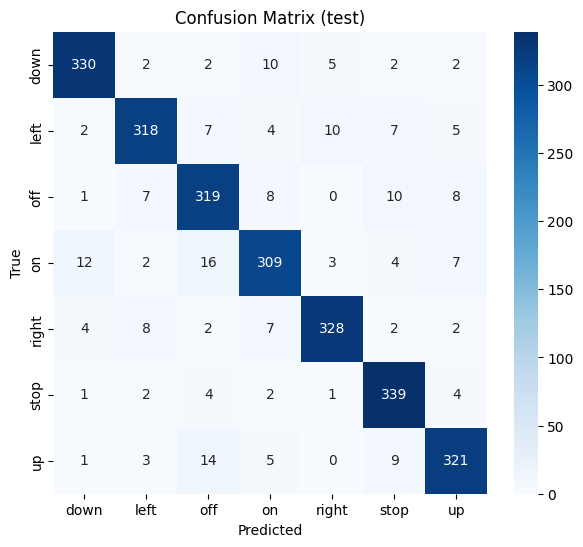

In [4]:
model.load_state_dict(torch.load("best_vit_speech.pt", map_location=device, weights_only=True))
model.eval()

all_preds = []
all_trues = []

with torch.no_grad():
    for x, y in tqdm(test_loader, desc="Inference"):
        x = x.to(device)
        out = model(x)
        pred = out.argmax(dim=1).cpu().numpy()
        all_preds.extend(pred)
        all_trues.extend(y.numpy())

print(classification_report(all_trues, all_preds, labels=list(range(NUM_CLASSES)), target_names=CLASSES, zero_division=0, digits=4))


cm = confusion_matrix(all_trues, all_preds, labels=list(range(NUM_CLASSES)))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix (test)')
plt.show()